# P3: visualizaciones exploratorias de patrones y cobertura

Este notebook genera dos visualizaciones previas al clustering usando los viajes de octubre de 2023 a septiembre de 2026: (1) el perfil semanal promedio por estación, separado en salidas y llegadas, y (2) la distribución de meses con actividad por estación. La primera resume el patrón temporal típico sin que las estaciones de mayor volumen dominen el resumen; la segunda muestra la cobertura desigual. No se ajustan ni muestran grupos de clustering.

Las figuras se muestran en el notebook y se guardan en `reports/figures/`. Solo se leen fechas, IDs de estaciones y mes de archivo; no se cargan datos personales ni filas de viajes en las salidas.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq

project_root = Path.cwd().resolve()
while not (project_root / "data" / "processed").is_dir() and project_root != project_root.parent:
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from proyecto_mibici.features_p3 import (
    PROFILE_COLUMNS,
    aggregate_p3_events,
    build_p3_station_profiles,
)

PARQUET_PATH = project_root / "data" / "processed" / "raw_data.parquet"
FIGURES_DIR = project_root / "reports" / "figures"
PERIOD_START = pd.Timestamp("2023-10-01")
PERIOD_END = pd.Timestamp("2026-10-01")
SOURCE_MONTH_START = "2023-10"
SOURCE_MONTH_END = "2026-09"
DAYS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]

if not PARQUET_PATH.is_file():
    raise FileNotFoundError(f"No se encontró el Parquet: {PARQUET_PATH}")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

2026-10-18 17:39:32.344 | INFO     | proyecto_mibici.config:<module>:11 - PROJ_ROOT path is: /Users/beibibumer/Documents/GitHub/TC5061-Proyecto-Equipo25


## Crear perfiles de estación

Se reutilizan las funciones de `features_p3.py`. Las filas del Parquet se leen por lotes y se limitan al mes de archivo acordado. Cada evento se asigna al mes de su marca de tiempo; por eso las llegadas que ocurren después del 1 de octubre de 2026 no entran en la ventana aunque su viaje empezara en septiembre.

In [2]:
required_columns = [
    "Inicio_del_viaje",
    "Fin_del_viaje",
    "Origen_Id",
    "Destino_Id",
    "mes_archivo",
]
event_chunks = []
audit_totals = {}
parquet_file = pq.ParquetFile(PARQUET_PATH)

for batch in parquet_file.iter_batches(batch_size=250_000, columns=required_columns):
    trips = batch.to_pandas()
    trips = trips.loc[
        trips["mes_archivo"].between(SOURCE_MONTH_START, SOURCE_MONTH_END)
    ]
    if trips.empty:
        continue

    counts, audit = aggregate_p3_events(
        trips,
        start=PERIOD_START,
        end=PERIOD_END,
    )
    for name, value in audit.items():
        audit_totals[name] = audit_totals.get(name, 0) + int(value)
    if not counts.empty:
        event_chunks.append(counts)

event_counts = (
    pd.concat(event_chunks, ignore_index=True)
    .groupby(
        ["estacion", "mes", "direccion", "dia_semana", "hora"],
        observed=True,
        as_index=False,
    )["viajes"]
    .sum()
)
profiles, station_descriptors = build_p3_station_profiles(
    event_counts,
    start=PERIOD_START,
    end=PERIOD_END,
)
print(f"Viajes válidos auditados: {audit_totals['viajes_validos']:,}")
print(f"Llegadas que quedan fuera del rango: {audit_totals['llegadas_fuera_de_ventana']:,}")
print(f"Estaciones con perfil: {len(profiles)}")
print(f"Variables por perfil: {len(PROFILE_COLUMNS)}")

Viajes válidos auditados: 13,621,885
Llegadas que quedan fuera del rango: 17
Estaciones con perfil: 473
Variables por perfil: 336


## Matriz de calor: patrón semanal típico

Para cada franja semanal se promedian las proporciones de todas las estaciones con perfil definido. Se muestra el porcentaje promedio del total de eventos de una estación que ocurre en cada día-hora, separado entre salidas y llegadas. Cada estación aporta el mismo peso; no representa el volumen total de viajes del sistema.

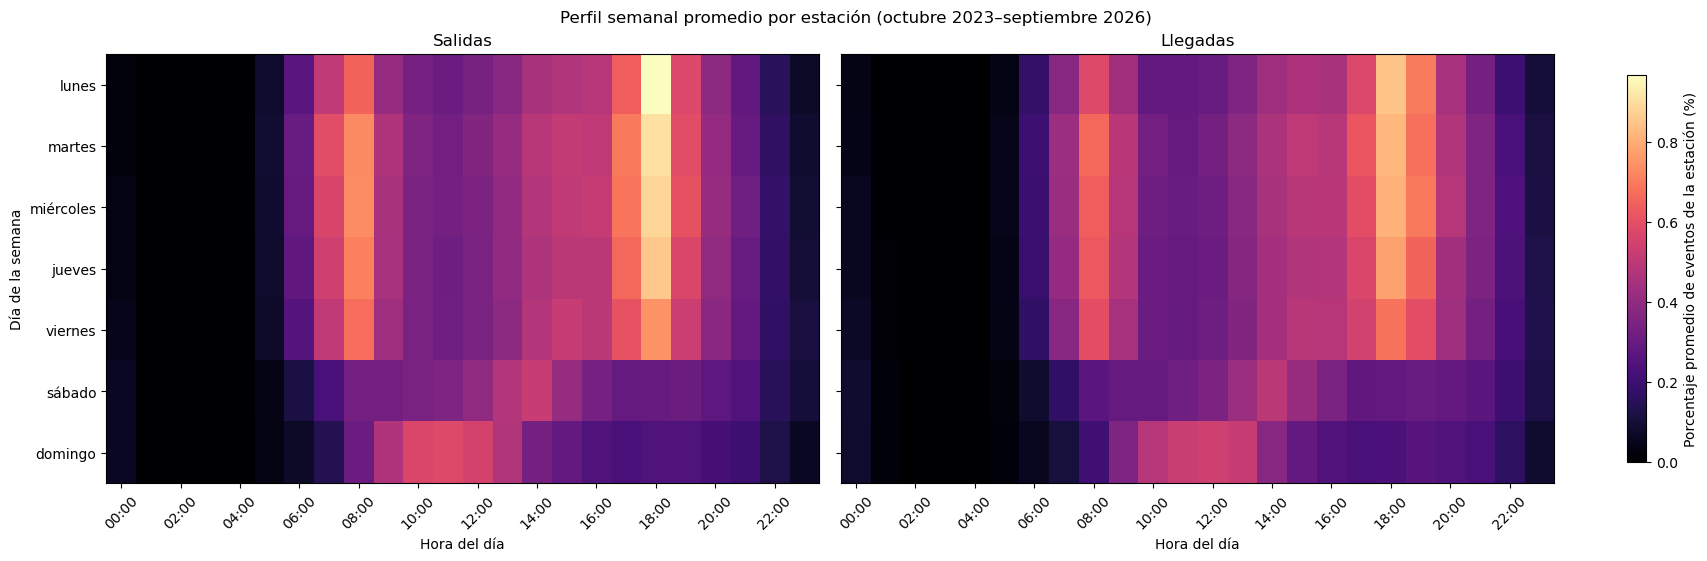

Figura guardada en: reports/figures/p3-perfil-semanal-promedio-estaciones.png


In [3]:
mean_profile = profiles.loc[:, PROFILE_COLUMNS].mean(axis=0).to_numpy()
mean_profile = mean_profile.reshape(2, 7, 24) * 100
color_max = mean_profile.max()

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True, constrained_layout=True)
for axis, direction, values in zip(axes, ["Salidas", "Llegadas"], mean_profile):
    image = axis.imshow(
        values,
        aspect="auto",
        interpolation="nearest",
        cmap="magma",
        vmin=0,
        vmax=color_max,
    )
    axis.set_title(direction)
    axis.set_xlabel("Hora del día")
    axis.set_xticks(range(0, 24, 2))
    axis.set_xticklabels([f"{hour:02d}:00" for hour in range(0, 24, 2)], rotation=45)
    axis.set_yticks(range(7))
    axis.set_yticklabels(DAYS)
axes[0].set_ylabel("Día de la semana")
colorbar = fig.colorbar(image, ax=axes, shrink=0.9)
colorbar.set_label("Porcentaje promedio de eventos de la estación (%)")
fig.suptitle("Perfil semanal promedio por estación (octubre 2023–septiembre 2026)")
heatmap_path = FIGURES_DIR / "p3-perfil-semanal-promedio-estaciones.png"
fig.savefig(heatmap_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Figura guardada en: {heatmap_path.relative_to(project_root)}")

## Distribución: meses con actividad por estación

Cada estación aporta el número de meses distintos (de los 36) en que tuvo al menos una salida o llegada observada. La gráfica muestra cobertura de actividad en los datos, no fechas oficiales de apertura/cierre de estaciones.

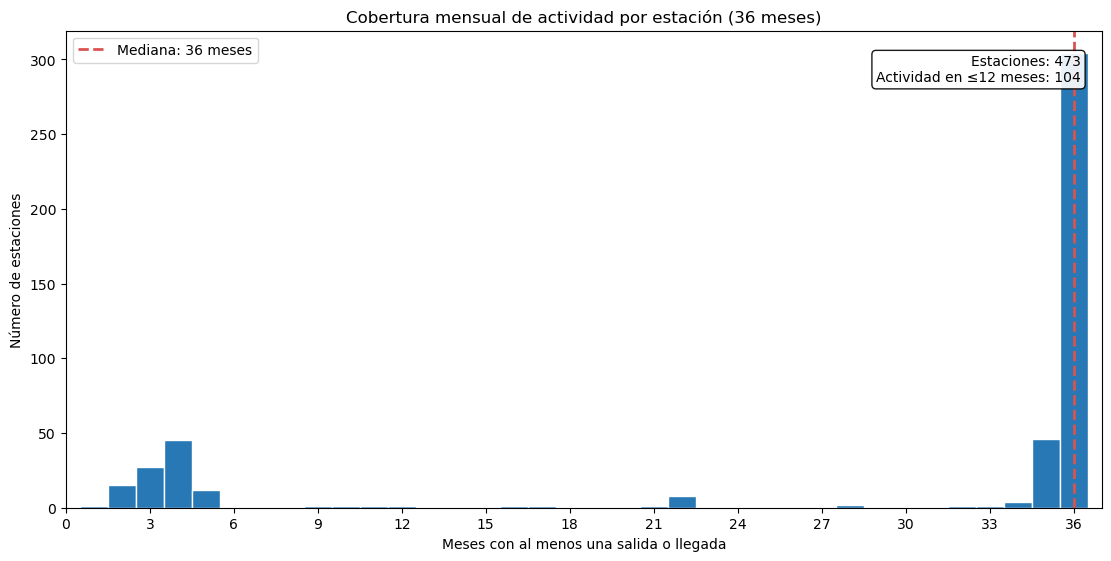

Figura guardada en: reports/figures/p3-cobertura-mensual-estaciones.png


In [4]:
coverage = station_descriptors["meses_con_actividad"]
median_coverage = coverage.median()
stations_at_most_12_months = int(coverage.le(12).sum())

fig, axis = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
axis.hist(
    coverage,
    bins=range(1, 39),
    color="#2878B5",
    edgecolor="white",
    align="left",
)
axis.axvline(
    median_coverage,
    color="#D9534F",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {median_coverage:.0f} meses",
)
axis.set(
    title="Cobertura mensual de actividad por estación (36 meses)",
    xlabel="Meses con al menos una salida o llegada",
    ylabel="Número de estaciones",
    xlim=(0, 37),
    xticks=range(0, 37, 3),
)
axis.legend()
axis.text(
    0.98,
    0.95,
    f"Estaciones: {len(coverage)}\n"
    f"Actividad en ≤12 meses: {stations_at_most_12_months}",
    transform=axis.transAxes,
    ha="right",
    va="top",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9},
)
coverage_path = FIGURES_DIR / "p3-cobertura-mensual-estaciones.png"
fig.savefig(coverage_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Figura guardada en: {coverage_path.relative_to(project_root)}")

## Interpretación para el siguiente paso

La matriz de calor permite verificar si el perfil propuesto muestra ritmos semanales y diferencias entre salidas/llegadas. La distribución de cobertura ayuda a decidir qué análisis de sensibilidad aplicar a estaciones con pocos meses observados. Ambas son diagnósticos exploratorios: no eligen el número de grupos ni sustituyen las métricas de clustering del punto 4.